In [1]:
%cd ../co-tracker
!mkdir checkpoints
%cd checkpoints
!wget https://huggingface.co/facebook/cotracker3/resolve/main/scaled_offline.pth
%cd ..

/home/dicia/python_code/co-trakcer_test/co-tracker


/home/dicia/dicia/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


mkdir: cannot create directory ‘checkpoints’: File exists
/home/dicia/python_code/co-trakcer_test/co-tracker/checkpoints
--2024-12-23 05:32:26--  https://huggingface.co/facebook/cotracker3/resolve/main/scaled_offline.pth
Resolving huggingface.co (huggingface.co)... 3.168.178.31, 3.168.178.101, 3.168.178.58, ...
Connecting to huggingface.co (huggingface.co)|3.168.178.31|:443... connected.
302 Foundest sent, awaiting response... 
Location: https://cdn-lfs-us-1.hf.co/repos/19/7a/197ad7e3e0455746500ab7ba04db277758846b3e1f222c3a3c6e8d6531ad85a6/2670d4562ed69326dda775a26e54883925cd11b6fc9b24cb7aa9f8078bce7834?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27scaled_offline.pth%3B+filename%3D%22scaled_offline.pth%22%3B&Expires=1735190103&Policy=eyJTdGF0ZW1lbnQiOlt7IkNvbmRpdGlvbiI6eyJEYXRlTGVzc1RoYW4iOnsiQVdTOkVwb2NoVGltZSI6MTczNTE5MDEwM319LCJSZXNvdXJjZSI6Imh0dHBzOi8vY2RuLWxmcy11cy0xLmhmLmNvL3JlcG9zLzE5LzdhLzE5N2FkN2UzZTA0NTU3NDY1MDBhYjdiYTA0ZGIyNzc3NTg4NDZiM2UxZjIyMmMzYTNjNmU4ZDY1

In [2]:
import os
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from base64 import b64encode
from IPython.display import HTML
from IPython.display import clear_output, display
from cotracker.predictor import CoTrackerPredictor
from cotracker.utils.visualizer import Visualizer, read_video_from_path
import torch.nn.functional as F
from ultralytics import YOLO

In [3]:
# 영상 로드
video = read_video_from_path('../data/sample22.avi')
print(video.shape)

# 첫번째 프레임 저장
first_frame = video[0]

# 영상 전처리
video = torch.from_numpy(video).permute(0, 3, 1, 2)[None].float()
print(video.shape)

# 해상도 줄이기
# video = F.interpolate(video[0], [540, 960], mode="bilinear")[None]
# print(video.shape)

# 프레임 줄이기
video = video[:, ::5]
print(video.shape)

def show_video(video_path):
    video_file = open(video_path, "r+b").read()
    video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"
    return HTML(f"""<video width="640" height="480" autoplay loop controls><source src="{video_url}"></video>""")

(195, 1080, 1920, 3)
torch.Size([1, 195, 3, 1080, 1920])
torch.Size([1, 39, 3, 1080, 1920])


In [4]:
# 모델 객체 생성
model = CoTrackerPredictor(
    checkpoint=os.path.join(
        './checkpoints/scaled_offline.pth'
    )
)

# YOLOv8 모델 로드
box_model = YOLO("yolov8n.pt")
seg_model = YOLO("yolov8n-seg.pt")

# 모델을 CUDA로 이동
if torch.cuda.is_available():
    print('cuda available')
    model = model.cuda()
    video = video.cuda()
    box_model = box_model.cuda()
    seg_model = seg_model.cuda()

cuda available


In [120]:
# 점 간격 설정
dot_spacing = 10

# 여백 크기 설정(여백 설정 안하면 세그가 탐지를 잘 못함)
padding = 20

# 추적 좌표 리스트 초기화
# seg_list = []
query_groups_dict = {}

# 원본 이미지 크기 저장 (나중에 좌표 보정에 사용)
original_height, original_width = first_frame.shape[:2]

# 이미지 640x640으로 리사이즈(YOLO 모델이 32 배수로 된 이미지가 아니면 처리를 못함)
image_resized = cv2.resize(first_frame, (640, 640))

# 이미지를 torch tensor로 변환하고 CUDA 장치로 이동
image_tensor = torch.from_numpy(image_resized).permute(2, 0, 1).unsqueeze(0).float() / 255.0
if torch.cuda.is_available():
    image_tensor = image_tensor.cuda()

# 이미지에서 객체 탐지
results = box_model(image_tensor)

# 탐지 결과 처리
for i, result in enumerate(results[0].boxes):
    box = result.xyxy[0].cpu().numpy()  # (x1, y1, x2, y2)
    cls = int(result.cls)  # 클래스 ID
    conf = result.conf.item()  # 신뢰도
    label = box_model.names[cls]  # 클래스 이름

    if label == "person" and conf >= 0.8:  # 사람 클래스만 필터링
        x1, y1, x2, y2 = map(int, box)        
        
        x1 = max(0, x1 - padding)  # 왼쪽 여백
        x2 = min(image_resized.shape[1], x2 + padding)  # 오른쪽 여백
        
        y1 = max(0, y1 - padding)  # 위쪽 여백
        y2 = min(image_resized.shape[0], y2 + padding)  # 아래쪽 여백

        # 바운딩 박스 내 이미지 잘라내기
        cropped_image = image_resized[y1:y2, x1:x2]
        cropped_resized = cv2.resize(cropped_image, (640, 640))

        # 이미지를 torch tensor로 변환하고 CUDA 장치로 이동
        cropped_tensor = (
            torch.from_numpy(cropped_resized).permute(2, 0, 1).unsqueeze(0).float() / 255.0
        )
        if torch.cuda.is_available():
            cropped_tensor = cropped_tensor.cuda()
        
        # 세그멘테이션 모델 실행
        seg_results = seg_model(cropped_tensor)
        
        # 세그멘테이션 마스크 확인
        if seg_results[0].masks is not None:  # 마스크가 유효한 경우에만 진행
            mask = seg_results[0].masks.data[0].cpu().numpy()  # 첫 번째 결과의 마스크
            mask_resized = cv2.resize(mask, (x2 - x1, y2 - y1))  # 원래 바운딩 박스 크기로 리사이즈
        
            # 마스크가 있는 영역에만 점 그리기
            for y in range(y1, y2, dot_spacing):  # Y축 방향 점 배치
                for x in range(x1, x2, dot_spacing):  # X축 방향 점 배치
                    # 마스크 내부 여부 확인
                    mask_x = x - x1
                    mask_y = y - y1
                    if mask_resized[mask_y, mask_x] > 0.9:  # 마스크 영역 안인지 확인
                        # 추적 id, 좌표 설정
                        if i not in query_groups_dict:
                            query_groups_dict[i] = []
                        query_groups_dict[i].append([x*original_width/640, y*original_height/640])

        else:
            print(f"No valid mask found for box {box}")


0: 640x640 4 persons, 1 frisbee, 1 tv, 9.7ms
Speed: 0.1ms preprocess, 9.7ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 8.3ms
Speed: 0.0ms preprocess, 8.3ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 7.1ms
Speed: 0.0ms preprocess, 7.1ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)


In [121]:
# 추적 좌표 그룹 텐서로 변환
query_groups = [{'id': i, 'query': torch.tensor([[0.0] + row for row in values])[None]}
                for i, values in query_groups_dict.items()]

# 좌표 그룹 합체
query_combined = torch.cat([group['query'] for group in query_groups], dim=1)

for key in query_groups_dict.keys():
    print('id: ', key, '\nquery: ', len(query_groups_dict[key]))
query_combined.shape

id:  0 
query:  154
id:  1 
query:  249


torch.Size([1, 403, 3])

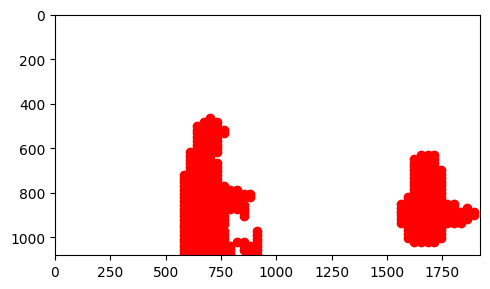

In [122]:
# 추적 좌표 cuda로 옮기기
query_combined = query_combined.squeeze(0)
if torch.cuda.is_available():
    query_combined = query_combined.cuda()

# 죄표 확인
fig, ax = plt.subplots(figsize=(5, 3))
for query in query_combined:
    ax.plot(query[1].item(), query[2].item(), 'ro')
    ax.set_xlim(0, 1920)
    ax.set_ylim(0, 1080)
    ax.invert_yaxis()
    
plt.tight_layout()
plt.show()

In [129]:
print(next(model.parameters()).device)  
print(video.device, query_combined.device)

cuda:0
cuda:0 cuda:0


In [136]:
# 모델 추론
pred_tracks, pred_visibility = model(video, queries=query_combined[None])

# 그룹에 따른 결과 저장 dict
results_tracks = {}
results_visibility = {}

# combined tensor의 인덱스
current_index = 0

for group in query_groups:
    num_queries = group['query'].shape[1]
    group_id = group['id']

    # 각 그룹의 결과 저장
    results_tracks[group_id] = pred_tracks[:, :, current_index:current_index + num_queries, :]
    results_visibility[group_id] = pred_visibility[:, :, current_index:current_index + num_queries]
    
    current_index += num_queries

In [137]:
# Visualizer 초기화
vis = Visualizer(
    save_dir='../result',
    linewidth=6,
    mode='cool',
    tracks_leave_trace=-1
)

vis.visualize(
    video=video,
    tracks=pred_tracks, # results_tracks[group_id]
    visibility=pred_visibility, # results_visibility[group_id]
    filename='rec_whole');
show_video("../result/rec_whole.mp4")

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1920, 1080) to (1920, 1088) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Video saved to ../result/rec_whole.mp4


In [150]:
video_path = "../result/rec_whole.mp4"
output_path = "../result/groupped.mp4"

# 전체 좌표의 평균 구하기
def calculate_centroid(track_points):
    centroid = np.mean(track_points, axis=0)
    return centroid

cap = cv2.VideoCapture(video_path)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# 코덱 설정, VideoWriter 객체 생성
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret: 
        break

    for group_id, tracks in results_tracks.items():
        # 현재 프레임의 추적 좌표를 구한다
        track_points = tracks[0, frame_idx]

        # 좌표 평균 계산
        centroid = calculate_centroid(track_points.cpu().numpy())

        # 좌표에 라벨 그리기
        label = group_id
        position = tuple(map(int, centroid))
        cv2.putText(frame, label, position, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # 프레임에 라벨 추가
    out.write(frame)
    frame_idx += 1

cap.release()
out.release()
cv2.destroyAllWindows()        



error: OpenCV(4.10.0) :-1: error: (-5:Bad argument) in function 'putText'
> Overload resolution failed:
>  - Can't convert object to 'str' for 'text'
>  - Can't convert object to 'str' for 'text'


In [45]:
pred_tracks.shape

torch.Size([1, 39, 403, 2])

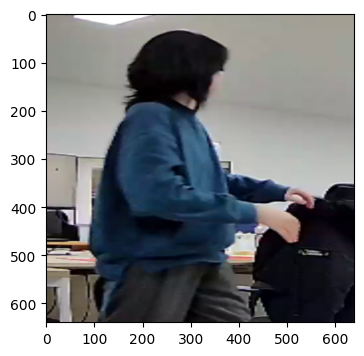

In [42]:
plt.figure(figsize=(4, 4))
plt.imshow(cropped_resized)


0: 640x640 4 persons, 1 bottle, 2 tvs, 7.8ms
Speed: 0.1ms preprocess, 7.8ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 1 backpack, 4.0ms
Speed: 0.0ms preprocess, 4.0ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 4.6ms
Speed: 0.0ms preprocess, 4.6ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


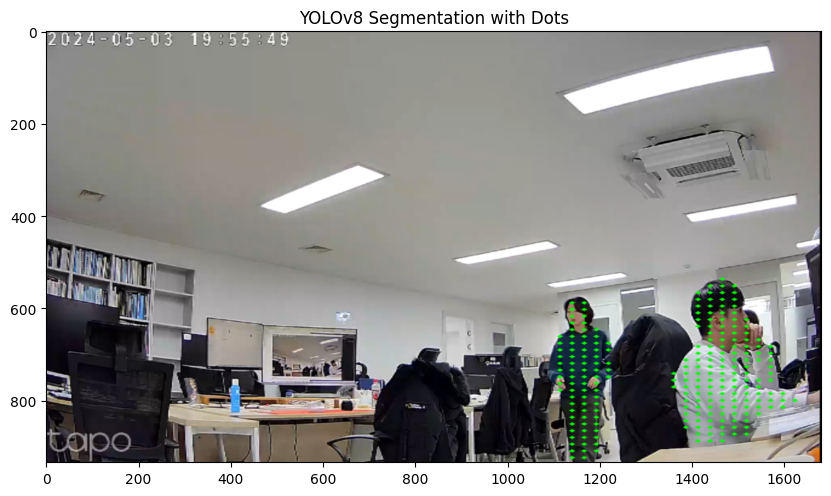

In [40]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import torch

# YOLOv8 모델 로드
box_model = YOLO("yolov8n.pt")
seg_model = YOLO("yolov8n-seg.pt")

# 모델을 CUDA로 이동
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
box_model.to(device)
seg_model.to(device)

# 이미지 읽기
image_path = "../data/test.png"
image = cv2.imread(image_path)

# 점 간격 설정
dot_spacing = 10

# 세그 좌표 리스트 초기화
queries = []

# OpenCV BGR -> RGB로 변환
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 원본 이미지 크기 저장 (나중에 좌표 보정에 사용)
original_height, original_width = image.shape[:2]

# 이미지 640x640으로 리사이즈(YOLO 모델이 32 배수로 된 이미지가 아니면 처리를 못함)
image_resized = cv2.resize(image_rgb, (640, 640))

# 이미지를 torch tensor로 변환하고 CUDA 장치로 이동
image_tensor = torch.from_numpy(image_resized).permute(2, 0, 1).unsqueeze(0).float().to(device) / 255.0

# 이미지에서 객체 탐지
results = box_model(image_tensor)

# 탐지 결과 처리
for result in results[0].boxes:
    box = result.xyxy[0].cpu().numpy()  # (x1, y1, x2, y2)
    cls = int(result.cls)  # 클래스 ID
    conf = result.conf.item()  # 신뢰도
    label = box_model.names[cls]  # 클래스 이름

    if label == "person" and conf >= 0.8:  # 사람 클래스만 필터링
        x1, y1, x2, y2 = map(int, box)

        # 여백 크기 설정(여백 설정 안하면 세그가 탐지를 잘 못함)
        padding = 10
        
        x1 = max(0, x1 - padding)  # 왼쪽 여백
        x2 = min(image_resized.shape[1], x2 + padding)  # 오른쪽 여백
        
        y1 = max(0, y1 - padding)  # 위쪽 여백
        y2 = min(image_resized.shape[0], y2 + padding)  # 아래쪽 여백

        # 바운딩 박스 내 이미지 잘라내기
        cropped_image = image_resized[y1:y2, x1:x2]
        cropped_resized = cv2.resize(cropped_image, (640, 640))

        # 세그멘테이션 모델 실행
        cropped_tensor = (
            torch.from_numpy(cropped_resized).permute(2, 0, 1).unsqueeze(0).float().to(device) / 255.0
        )
        seg_results = seg_model(cropped_tensor)
        
        # 세그멘테이션 마스크 확인
        if seg_results[0].masks is not None:  # 마스크가 유효한 경우에만 진행
            mask = seg_results[0].masks.data[0].cpu().numpy()  # 첫 번째 결과의 마스크
            mask_resized = cv2.resize(mask, (x2 - x1, y2 - y1))  # 원래 바운딩 박스 크기로 리사이즈
        
            # 마스크가 있는 영역에만 점 그리기
            for y in range(y1, y2, dot_spacing):  # Y축 방향 점 배치
                for x in range(x1, x2, dot_spacing):  # X축 방향 점 배치
                    # 마스크 내부 여부 확인
                    mask_x = x - x1
                    mask_y = y - y1
                    if mask_resized[mask_y, mask_x] > 0.9:  # 마스크 영역 안인지 확인
                        cv2.circle(image_resized, (x, y), 2, (0, 255, 0), -1)
                        queries.append([x*original_width/640, y*original_height/640])

        else:
            print(f"No valid mask found for box {box}")

# 이미지 원본 비율로 되돌리기
result_image = cv2.resize(image_resized, (original_width, original_height))

plt.figure(figsize=(10, 6))
plt.imshow(result_image)
# plt.axis("off")
plt.title("YOLOv8 Segmentation with Dots")
plt.show()

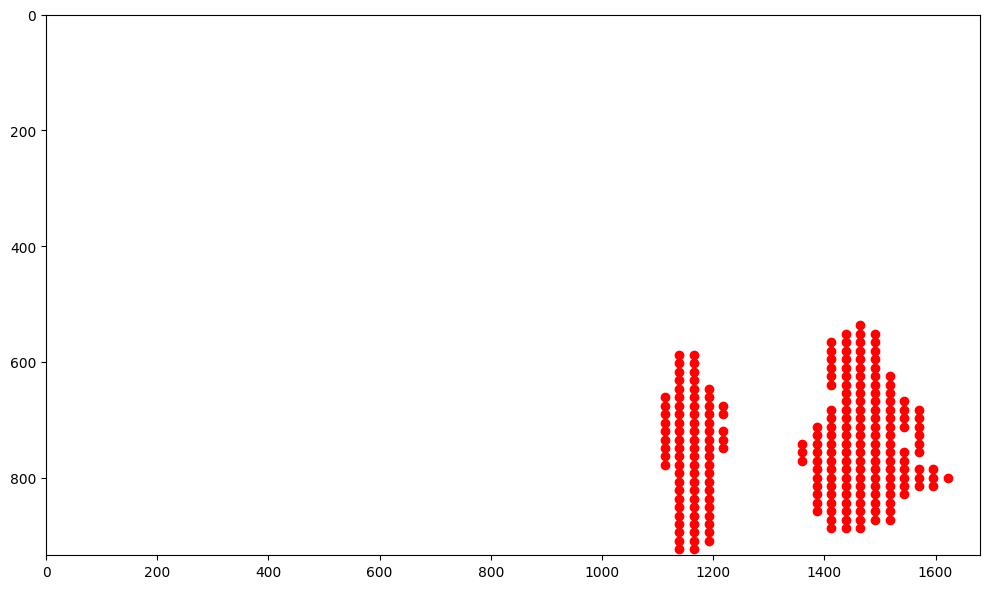

In [57]:
fig, ax = plt.subplots(figsize=(10, 6))
for query in queries:
    ax.plot(query[0], query[1], 'ro')
    ax.set_xlim(0, original_width)
    ax.set_ylim(0, original_height)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()